In [9]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
import keras_tuner as kt

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


## 1. Data Ingestion & Custom Labeling
We load the dataset from `d:\WIFI-HAR




all_detection_amrith` and apply specific labeling rules:
- `amrith_falling_01.csv` & `02.csv`: First 5 records are Rest (0), remaining are Fall (1).
- `amrith_falling_03.csv` to `25.csv`: First 30 records are Rest (0), remaining are Fall (1).
- `amrith_rest_01.csv`: All records are Rest (0).


In [10]:
DATA_DIR = "d:/WIFI-HAR/fall_detection_amrith"
def process_csi_string(csi_str):
    # Remove brackets and convert to numpy array of integers
    clean_str = csi_str.replace('[', '').replace(']', '').strip()
    # Handle multiple spaces
    clean_str = ' '.join(clean_str.split())
    csi_data = np.fromstring(clean_str, sep=' ', dtype=int)
    
    # Standard ESP32 format: even indices are imaginary, odd are real
    imag = csi_data[0::2]
    real = csi_data[1::2]
    
    # Calculate Amplitude
    amplitude = np.sqrt(imag**2 + real**2)
    phase = np.arctan2(imag, real)
    
    # Pad or truncate to 128 subcarriers
    target_len = 128
    if len(amplitude) < target_len:
        padded_amp = np.zeros(target_len)
        padded_amp[:len(amplitude)] = amplitude
        amplitude = padded_amp
        
        padded_phase = np.zeros(target_len)
        padded_phase[:len(phase)] = phase
        phase = padded_phase
    elif len(amplitude) > target_len:
        amplitude = amplitude[:target_len]
        phase = phase[:target_len]
        
    return amplitude, phase

X_list = []
X_phase_list = []
y_list = []

# Read all CSVs
all_files = glob.glob(os.path.join(DATA_DIR, "*.csv"))

for file_path in all_files:
    filename = os.path.basename(file_path)
    try:
        df = pd.read_csv(file_path)
    except Exception as e:
        print(f"Could not read {filename}: {e}")
        continue
        
    if 'CSI_DATA' not in df.columns:
        print(f"'CSI_DATA' column missing in {filename}")
        continue
        
    for idx, row in df.iterrows():
        csi_str = str(row['CSI_DATA'])
        if csi_str == 'nan' or not csi_str:
            continue
            
        amplitude, phase = process_csi_string(csi_str)
        
        # Determine label based on rules
        label = 0 # Default Rest
        
        if "amrith_rest" in filename:
            label = 0
        elif "amrith_falling_01.csv" in filename or "amrith_falling_02.csv" in filename:
            if idx >= 5:
                label = 1
        elif "amrith_falling_" in filename:
            if idx >= 30:
                label = 1
                
        X_list.append(amplitude)
        X_phase_list.append(phase)
        y_list.append(label)

X = np.array(X_list)
X_phase = np.array(X_phase_list)
y = np.array(y_list)

print(f"Total samples loaded: {X.shape[0]}")
print(f"Data shape: {X.shape}")
print(f"Labels shape: {y.shape}")


Total samples loaded: 2343
Data shape: (2343, 128)
Labels shape: (2343,)


## 2. Exploratory Data Analysis (EDA)
Visualizing class distributions and sample CSI Amplitude across Subcarriers.


C:\Users\ASUS\AppData\Local\Temp\ipykernel_29804\642553158.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette='viridis')


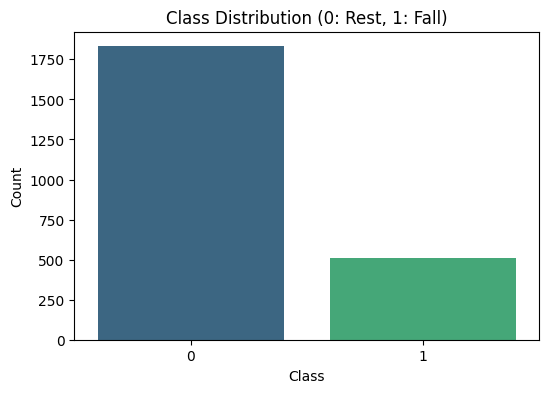

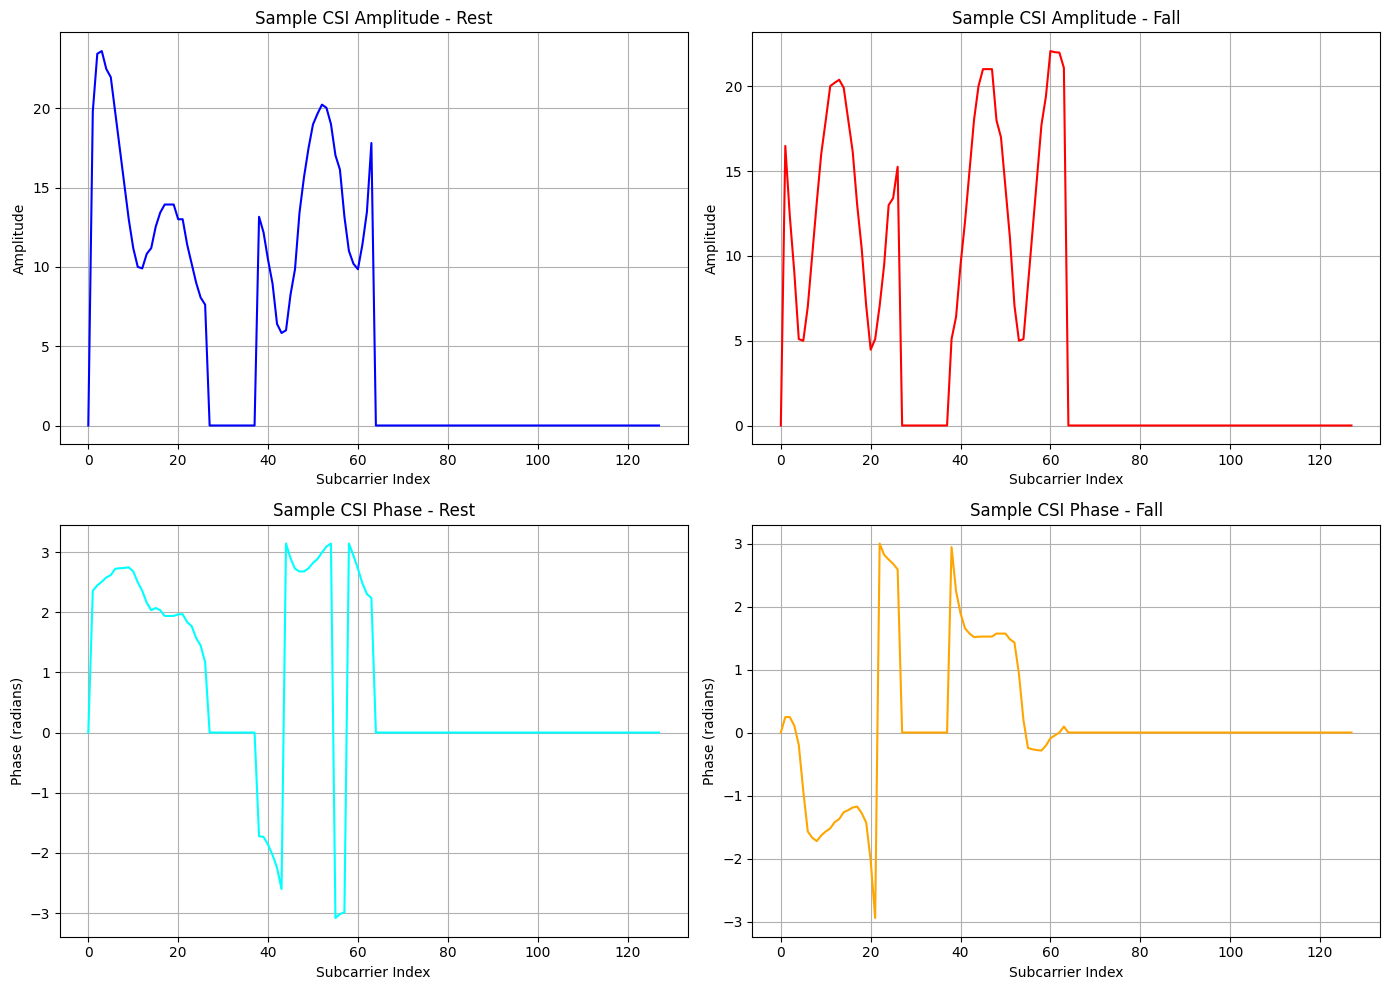

In [11]:
# Check if data was loaded
if len(y) == 0:
    print("⚠️ Error: The 'y' array is empty. Please ensure Cell 2 was executed and DATA_DIR is correct.")
else:
    # Class Distribution
    plt.figure(figsize=(6, 4))
    sns.countplot(x=y, palette='viridis')
    plt.title('Class Distribution (0: Rest, 1: Fall)')
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.show()
    
    # Safely find indices for Rest and Fall
    rest_indices = np.where(y == 0)[0]
    fall_indices = np.where(y == 1)[0]
    
    if len(rest_indices) == 0:
        print("⚠️ Error: No 'Rest' (0) samples found in the dataset.")
    elif len(fall_indices) == 0:
        print("⚠️ Error: No 'Fall' (1) samples found in the dataset.")
    else:
        # Visualize Sample Amplitude and Phase if both exist
        rest_idx = rest_indices[0]
        fall_idx = fall_indices[0]
        
        plt.figure(figsize=(14, 10))
        
        # Amplitude Plot - Rest
        plt.subplot(2, 2, 1)
        plt.plot(X[rest_idx], color='blue')
        plt.title('Sample CSI Amplitude - Rest')
        plt.xlabel('Subcarrier Index')
        plt.ylabel('Amplitude')
        plt.grid(True)
        
        # Amplitude Plot - Fall
        plt.subplot(2, 2, 2)
        plt.plot(X[fall_idx], color='red')
        plt.title('Sample CSI Amplitude - Fall')
        plt.xlabel('Subcarrier Index')
        plt.ylabel('Amplitude')
        plt.grid(True)
        
        # Phase Plots (Only render if X_phase was successfully created in Cell 2)
        if 'X_phase' in locals() or 'X_phase' in globals():
            # Phase Plot - Rest
            plt.subplot(2, 2, 3)
            plt.plot(X_phase[rest_idx], color='cyan')
            plt.title('Sample CSI Phase - Rest')
            plt.xlabel('Subcarrier Index')
            plt.ylabel('Phase (radians)')
            plt.grid(True)
            
            # Phase Plot - Fall
            plt.subplot(2, 2, 4)
            plt.plot(X_phase[fall_idx], color='orange')
            plt.title('Sample CSI Phase - Fall')
            plt.xlabel('Subcarrier Index')
            plt.ylabel('Phase (radians)')
            plt.grid(True)
        else:
            print("⚠️ Warning: X_phase array not found. Please ensure Cell 2 extracts and saves the phase data.")
            
        plt.tight_layout()
        plt.show()


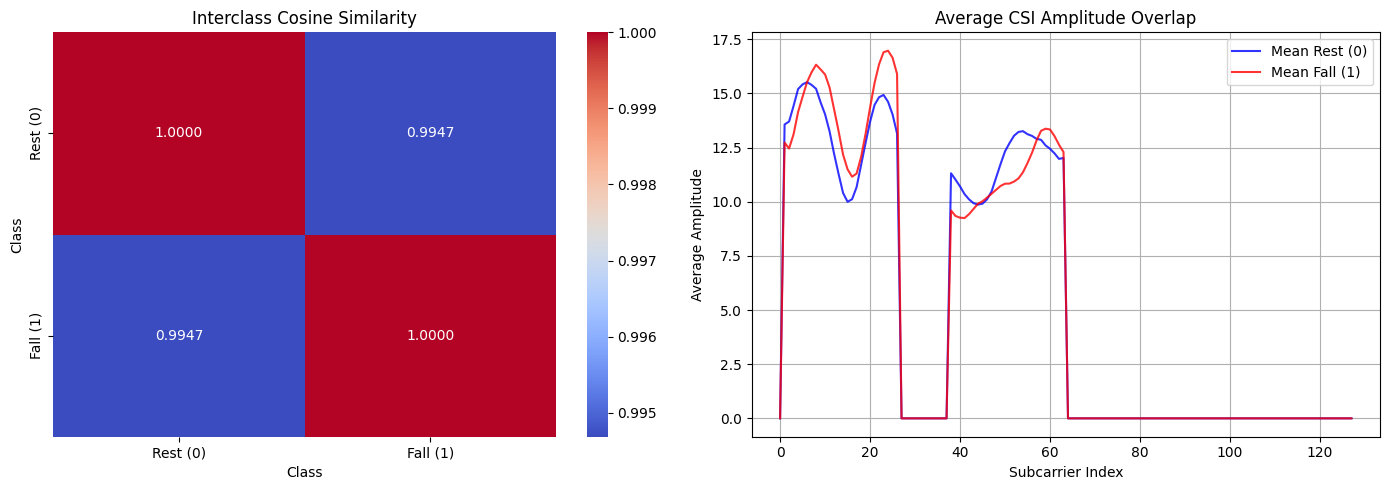

In [12]:
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Calculate the average CSI amplitude signature for each class
mean_rest = np.mean(X[y == 0], axis=0)
mean_fall = np.mean(X[y == 1], axis=0)

# Combine into a single matrix for mathematical comparison
class_means = np.vstack([mean_rest, mean_fall])

# 2. Calculate the Cosine Similarity Matrix between the two classes
similarity_matrix = cosine_similarity(class_means)

plt.figure(figsize=(14, 5))

# 3. Plot the Interclass Similarity Heatmap
plt.subplot(1, 2, 1)
sns.heatmap(similarity_matrix, annot=True, fmt='.4f', cmap='coolwarm', 
            xticklabels=['Rest (0)', 'Fall (1)'], 
            yticklabels=['Rest (0)', 'Fall (1)'])
plt.title('Interclass Cosine Similarity')
plt.xlabel('Class')
plt.ylabel('Class')

# 4. Plot the Mean Signature Overlay to physically see the overlap
plt.subplot(1, 2, 2)
plt.plot(mean_rest, label='Mean Rest (0)', color='blue', alpha=0.8)
plt.plot(mean_fall, label='Mean Fall (1)', color='red', alpha=0.8)
plt.title('Average CSI Amplitude Overlap')
plt.xlabel('Subcarrier Index')
plt.ylabel('Average Amplitude')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 3. Preprocessing
We scale the data using standard scaling and reshape it for the 1D CNN.


In [13]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Reshape for 1D CNN: (samples, time_steps, features)
# Here, subcarriers act as our spatial/time steps
X_train_cnn = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_test_cnn = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

print(f"X_train shape: {X_train_cnn.shape}")
print(f"X_test shape: {X_test_cnn.shape}")


X_train shape: (1874, 128, 1)
X_test shape: (469, 128, 1)


In [14]:
print("MEAN_ARRAY =", list(scaler.mean_))
print("STD_ARRAY =", list(scaler.scale_))

MEAN_ARRAY = [np.float64(0.0), np.float64(13.381601939841076), np.float64(13.44597851148424), np.float64(14.146513962356645), np.float64(14.995911461818844), np.float64(15.30759950811874), np.float64(15.539825368151952), np.float64(15.53250657271049), np.float64(15.463289961173192), np.float64(14.910553354758425), np.float64(14.419181743823334), np.float64(13.664686326911548), np.float64(12.649280073988894), np.float64(11.710890371401893), np.float64(10.806091568830356), np.float64(10.358712634285498), np.float64(10.383481598788157), np.float64(10.851999832576528), np.float64(11.822112656814738), np.float64(12.842921233260785), np.float64(13.853807834506558), np.float64(14.703971473388588), np.float64(15.161185516704714), np.float64(15.349963135784098), np.float64(15.115684379010856), np.float64(14.59185575703951), np.float64(13.745953578133722), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.fl

## 4. Baseline Model (Random Forest)
Before training a complex CNN, we train a standard Random Forest classifier to serve as a baseline for performance.


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train Random Forest on the scaled 2D data
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_baseline.fit(X_train_scaled, y_train)

# Predict on test set
y_pred_rf = rf_baseline.predict(X_test_scaled)

# Print baseline results
print("--- Baseline Random Forest Results ---")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf))


--- Baseline Random Forest Results ---
Accuracy: 0.8081023454157783

Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.98      0.89       367
           1       0.73      0.19      0.30       102

    accuracy                           0.81       469
   macro avg       0.77      0.58      0.59       469
weighted avg       0.79      0.81      0.76       469



## 5. Hyperparameter Optimization & CNN Architecture
Using `keras-tuner` to find the optimal filters, kernel sizes, and learning rate.


In [16]:
def build_model(hp):
    model = Sequential()
    
    # Tuning first Convolutional Layer
    hp_filters_1 = hp.Int('filters_1', min_value=32, max_value=128, step=32)
    hp_kernel_1 = hp.Choice('kernel_1', values=[3, 5, 7])
    model.add(Conv1D(filters=hp_filters_1, kernel_size=hp_kernel_1, activation='relu', input_shape=(128, 1)))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    
    # Tuning second Convolutional Layer
    hp_filters_2 = hp.Int('filters_2', min_value=32, max_value=128, step=32)
    hp_kernel_2 = hp.Choice('kernel_2', values=[3, 5])
    model.add(Conv1D(filters=hp_filters_2, kernel_size=hp_kernel_2, activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    
    model.add(Flatten())
    
    # Dense layer
    hp_units = hp.Int('units', min_value=64, max_value=256, step=64)
    model.add(Dense(units=hp_units, activation='relu'))
    model.add(BatchNormalization())
    
    hp_dropout = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1)
    model.add(Dropout(rate=hp_dropout))
    
    model.add(Dense(1, activation='sigmoid'))
    
    # Tuning learning rate
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    
    return model

# Initialize tuner
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=15, # Can be increased for better optimization
    executions_per_trial=1,
    directory='tuner_logs',
    project_name='wifi_csi_fall_detection',
    overwrite=True
)

tuner.search_space_summary()


Search space summary
Default search space size: 7
filters_1 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
kernel_1 (Choice)
{'default': 3, 'conditions': [], 'values': [3, 5, 7], 'ordered': True}
filters_2 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
kernel_2 (Choice)
{'default': 3, 'conditions': [], 'values': [3, 5], 'ordered': True}
units (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 256, 'step': 64, 'sampling': 'linear'}
dropout (Float)
{'default': 0.2, 'conditions': [], 'min_value': 0.2, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## 6. Training the Best Model


In [17]:

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Search for best hyperparameters
tuner.search(X_train_cnn, y_train, epochs=20, validation_split=0.2, callbacks=[early_stop], verbose=1)

# Get best model
best_model = tuner.get_best_models(num_models=1)[0]
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\n--- Best CNN Hyperparameters ---")
for hp_name, hp_value in best_hps.values.items():
    print(f"{hp_name}: {hp_value}")
print("--------------------------------\n")

# Retrain model with best hyperparameters for a full set of epochs
history = best_model.fit(X_train_cnn, y_train, epochs=50, validation_split=0.2, callbacks=[early_stop], verbose=1)


Trial 15 Complete [00h 00m 05s]
val_accuracy: 0.7733333110809326

Best val_accuracy So Far: 0.8106666803359985
Total elapsed time: 00h 02m 35s

--- Best CNN Hyperparameters ---
filters_1: 64
kernel_1: 3
filters_2: 96
kernel_2: 3
units: 192
dropout: 0.30000000000000004
learning_rate: 0.0001
--------------------------------

Epoch 1/50


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7872 - loss: 0.4633 - val_accuracy: 0.7600 - val_loss: 0.4922
Epoch 2/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7899 - loss: 0.4594 - val_accuracy: 0.8000 - val_loss: 0.4640
Epoch 3/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8165 - loss: 0.4162 - val_accuracy: 0.7760 - val_loss: 0.4872
Epoch 4/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8286 - loss: 0.4135 - val_accuracy: 0.7520 - val_loss: 0.5113
Epoch 5/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8412 - loss: 0.3901 - val_accuracy: 0.7627 - val_loss: 0.5029
Epoch 6/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8352 - loss: 0.3857 - val_accuracy: 0.7707 - val_loss: 0.4680
Epoch 7/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8399 - loss: 0.3736 - val_accuracy: 0.7787 - val_loss: 0.4529
Epoch 8/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8439 - loss: 0.3570 - val_accuracy: 0.7840 - val_loss: 0.4940

## 7. Model Evaluation & Results


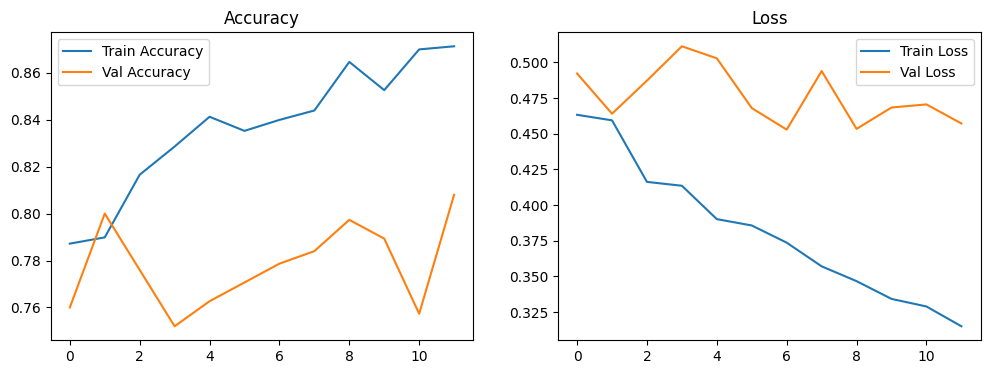

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Accuracy: 0.7803837953091685

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.89      0.86       367
           1       0.49      0.38      0.43       102

    accuracy                           0.78       469
   macro avg       0.67      0.64      0.65       469
weighted avg       0.76      0.78      0.77       469



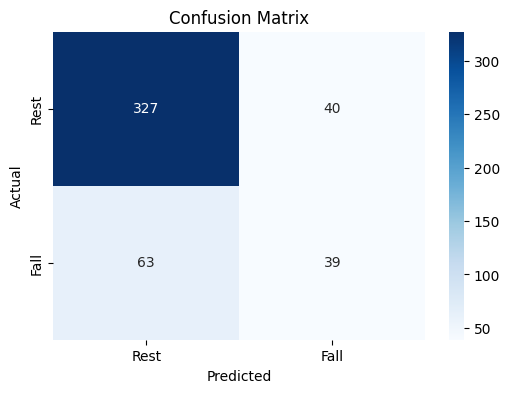

In [18]:
# Plot Training History
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss')
plt.show()

# Predictions
y_pred_prob = best_model.predict(X_test_cnn)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rest', 'Fall'], yticklabels=['Rest', 'Fall'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [20]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Automatically convert one-hot encoded arrays to class indices if needed
if y_test.ndim > 1 and y_test.shape[1] > 1:
    y_true_labels = np.argmax(y_test, axis=1)
else:
    y_true_labels = y_test

if y_pred.ndim > 1 and y_pred.shape[1] > 1:
    y_pred_labels = np.argmax(y_pred, axis=1)
else:
    y_pred_labels = y_pred

# Calculate the confusion matrix using y_true_labels and y_pred_labels
cm = confusion_matrix(y_true_labels, y_pred_labels)

# Number of classes
num_classes = cm.shape[0]

print("TP, TN, FP, FN for each class:\n" + "="*30)

for i in range(num_classes):
    # True Positives: diagonal element for the class
    tp = cm[i, i]
    
    # False Negatives: sum of the corresponding row, minus TP
    fn = np.sum(cm[i, :]) - tp
    
    # False Positives: sum of the corresponding column, minus TP
    fp = np.sum(cm[:, i]) - tp
    
    # True Negatives: total sum of the matrix, minus (TP + FP + FN)
    tn = np.sum(cm) - (tp + fp + fn)
    
    print(f"Class {i}:")
    print(f"  True Positives  (TP): {tp}")
    print(f"  True Negatives  (TN): {tn}")
    print(f"  False Positives (FP): {fp}")
    print(f"  False Negatives (FN): {fn}")
    print("-" * 30)


TP, TN, FP, FN for each class:
Class 0:
  True Positives  (TP): 327
  True Negatives  (TN): 39
  False Positives (FP): 63
  False Negatives (FN): 40
------------------------------
Class 1:
  True Positives  (TP): 39
  True Negatives  (TN): 327
  False Positives (FP): 40
  False Negatives (FN): 63
------------------------------


In [21]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# Generate predictions from the tuned CNN
y_pred_prob = best_model.predict(X_test_cnn)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Overall Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"--- Overall Accuracy: {acc:.4f} ---\n")

# Calculate class-wise metrics directly
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1])

# Print metrics for REST (Class 0)
print("[ Class 0 : Rest ]")
print(f"  Precision : {precision[0]:.4f}")
print(f"  Recall    : {recall[0]:.4f}")
print(f"  F1-Score  : {f1[0]:.4f}")
print(f"  Support   : {support[0]}")

# Print metrics for FALL (Class 1)
print("\n[ Class 1 : Fall ]")
print(f"  Precision : {precision[1]:.4f}")
print(f"  Recall    : {recall[1]:.4f}")
print(f"  F1-Score  : {f1[1]:.4f}")
print(f"  Support   : {support[1]}")


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
--- Overall Accuracy: 0.7804 ---

[ Class 0 : Rest ]
  Precision : 0.8385
  Recall    : 0.8910
  F1-Score  : 0.8639
  Support   : 367

[ Class 1 : Fall ]
  Precision : 0.4937
  Recall    : 0.3824
  F1-Score  : 0.4309
  Support   : 102


In [22]:
import numpy as np

# 1. Generate a random dummy record simulating 128 scaled subcarriers
# Shape required by the CNN: (batch_size, subcarriers, features) -> (1, 128, 1)
dummy_record = np.random.randn(1, 128, 1)

# 2. Predict using the trained model
# The output is a single probability value from the Sigmoid layer
probability = best_model.predict(dummy_record)[0][0]

# 3. Determine the class and calculate confidence
predicted_class = 1 if probability > 0.5 else 0
class_name = "Fall (1)" if predicted_class == 1 else "Rest (0)"

# Confidence is based on how certain the model is (close to 0 or close to 1)
if predicted_class == 1:
    confidence = probability
else:
    confidence = 1.0 - probability

# 4. Print the detailed results
print("--- Random Record Inference Test ---")
print(f"Predicted Class         : {class_name}")
print(f"Raw Sigmoid Output      : {probability:.6f}")
print(f"Probability of 'Fall'   : {probability * 100:.2f}%")
print(f"Overall Confidence      : {confidence * 100:.2f}%")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
--- Random Record Inference Test ---
Predicted Class         : Rest (0)
Raw Sigmoid Output      : 0.000010
Probability of 'Fall'   : 0.00%
Overall Confidence      : 100.00%


In [23]:
import os

# Choose a filename for your model
model_filename = "wifi_csi_fall_detection_model.keras"

# Save the trained model to the current directory (d:\WIFI-HAR)
best_model.save(model_filename)

print(f"✅ Model successfully saved locally as: {model_filename}")
print(f"Full path: {os.path.abspath(model_filename)}")

# Example of how you would load it in a different Python script or notebook in the future:
# from tensorflow.keras.models import load_model
# loaded_model = load_model("wifi_csi_fall_detection_model.keras")
# predictions = loaded_model.predict(new_data)


✅ Model successfully saved locally as: wifi_csi_fall_detection_model.keras
Full path: d:\WIFI-HAR\wifi_csi_fall_detection_model.keras
